<a href="https://colab.research.google.com/github/ririfka08/FinalTask_HomeCredit_DataScientist/blob/main/FinalTask_HomeCredit_Scorecard_Data_Scientist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Home Credit Indonesia: Credit Risk Scoring (Final Task Project Based Internship - Data Scientist)**


Home Credit ingin memanfaatkan data yang tersedia untuk meningkatkan proses prediksi skor kredit. Analisis dilakukan untuk mengidentifikasi pelanggan yang mampu melunasi pinjaman, sehingga keputusan pemberian pinjaman dapat mempertimbangkan hasil prediksi dari data. Selain mengurangi risiko gagal bayar, perlu dipastikan pelanggan yang mampu melunasi tidak ditolak, dan pinjaman diberikan dengan principal, maturity, dan repayment calendar yang sesuai dengan kemampuan mereka. Pada notebook ini akan melakukan analisis lengkap dari pemahaman masalah sampai dampak bisnis: eksplorasi data, pembersihan dan pembuatan fitur, insight, pemodelan dengan tuning, evaluasi, dan dampak bisnis.

1. Data application_train dibagi 60% train, 20% validation, dan 20% test dengan proporsi target yang sama.
2. Imputasi dan scaling berada di dalam Pipeline sehingga hanya dipelajari dari data train.
3. Tuning hyperparameter memakai cross validation di data train saja.
4. Threshold dipilih di validation, dan angka akhir dilaporkan di test.
5. Model tidak memakai class_weight atau SMOTE agar probabilitasnya tetap bermakna.

by **Rifka Umdati**

#**1. Setup dan Konfigurasi Path**
Menyiapkan semua yang dibutuhkan sebelum diproses. Mulai dari import library yang dibutuhkan, menentukan folder data (`DATA_DIR`), menetapkan asumsi bisnis (LGD dan margin) di satu tempat, dan membuat fungsi `read()`

In [6]:
# Import Library
import gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
SEED = 42

In [21]:
DATA_DIR = '/content/'

LGD = 0.45
MARGIN = 0.10

USE_BUREAU_BALANCE = True

def read(name, usecols=None):
    df = pd.read_csv(
        DATA_DIR + name,
        usecols=usecols,
        engine='c',
        low_memory=False
    )
    for c in df.select_dtypes('float64').columns:
        df[c] = df[c].astype('float32')
    return df

# **2. Load Dataset dan Konteks Masalah**

Home Credit ingin memanfaatkan data yang tersedia untuk meningkatkan proses prediksi skor kredit. Analisis dilakukan untuk mengidentifikasi pelanggan yang mampu melunasi pinjaman, sehingga keputusan pemberian pinjaman dapat mempertimbangkan hasil prediksi dari data. Selain mengurangi risiko gagal bayar, perlu dipastikan pelanggan yang mampu melunasi tidak ditolak, dan pinjaman diberikan dengan principal, maturity, dan repayment calendar yang sesuai dengan kemampuan mereka.

Overiview data:
* `application_train.csv` dan `application_test.csv`: Merupakan tabel utama yang berisi data statis setiap pengajuan pinjaman dalam sampel. `application_train.csv` memiliki kolom `TARGET` sebagai label untuk pemodelan, sedangkan `application_test.csv` tidak memiliki kolom tersebut dan digunakan untuk prediksi. Setiap baris merepresentasikan satu pinjaman dalam sampel.

* `bureau.csv`: Berisi informasi seluruh kredit nasabah sebelumnya yang diberikan oleh lembaga keuangan lain dan dilaporkan ke Credit Bureau. Untuk satu pinjaman dalam sampel, tabel ini dapat memiliki beberapa baris sesuai jumlah kredit nasabah yang tercatat di Credit Bureau sebelum tanggal pengajuan.

* `bureau_balance.csv`: Berisi riwayat saldo bulanan dari kredit sebelumnya yang tercatat di Credit Bureau. Setiap baris merepresentasikan catatan satu bulan untuk satu kredit sebelumnya, sehingga satu kredit dapat memiliki banyak baris berdasarkan periode riwayat yang tersedia.

* `previous_application.csv`: Berisi seluruh pengajuan pinjaman Home Credit sebelumnya dari nasabah yang memiliki pinjaman dalam sampel. Setiap baris merepresentasikan satu pengajuan sebelumnya yang berkaitan dengan pinjaman dalam sampel.

* `POS_CASH_balance.csv`: Berisi catatan saldo bulanan dari pinjaman POS (*point of sales*) dan pinjaman tunai sebelumnya yang dimiliki nasabah di Home Credit. Setiap baris merepresentasikan catatan satu bulan untuk satu pinjaman sebelumnya, sesuai riwayat yang tersedia.

* `credit_card_balance.csv`: Berisi catatan saldo bulanan dari kartu kredit sebelumnya yang dimiliki nasabah di Home Credit. Setiap baris merepresentasikan catatan satu bulan untuk satu kartu kredit sebelumnya, sesuai riwayat yang tersedia.

* `installments_payments.csv`: Berisi riwayat pembayaran cicilan dari kredit sebelumnya yang telah dicairkan oleh Home Credit dan berkaitan dengan pinjaman dalam sampel. Data mencakup setiap pembayaran yang dilakukan maupun setiap cicilan yang terlewat. Setiap baris merepresentasikan satu pembayaran atas suatu cicilan atau satu cicilan yang berkaitan dengan pembayaran pada kredit sebelumnya.

* `HomeCredit_columns_description.csv`: Berisi deskripsi kolom-kolom pada dataset untuk membantu memahami arti setiap variabel yang tersedia.


Pada bagian ini akan memuat application_train, menampilkan ukuran data, dan membaca definisi TARGET dari file deskripsi kolom. Tabel utama `application_train` dan `application_test` menggunakan `SK_ID_CURR` sebagai identitas pinjaman dalam sampel. Sementara itu, tabel riwayat kredit memiliki tingkat detail yang berbeda-beda dan dapat memuat beberapa baris untuk satu pinjaman. Karena itu, apabila informasi dari tabel-tabel tersebut akan digabungkan ke tabel utama untuk pemodelan, data riwayat perlu dirangkum melalui proses agregasi ke tingkat `SK_ID_CURR` terlebih dahulu agar setiap pinjaman tetap direpresentasikan oleh satu baris.


In [22]:
app = read('application_train.csv')
print('application_train:', app.shape)

col_desc = pd.read_csv(DATA_DIR + 'HomeCredit_columns_description.csv', encoding='latin1')
print('\nTARGET:', col_desc.loc[col_desc['Row'] == 'TARGET', 'Description'].values[0])
app.head()

application_train: (307511, 122)

TARGET: Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,...,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.0000","406,597.5000","24,700.5000","351,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,"-3,648.0000",-2120,NaN,1,1,0,1,1,0,Laborers,1.0000,...,2.0000,2.0000,2.0000,"-1,134.0000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,"270,000.0000","1,293,502.5000","35,698.5000","1,129,500.0000",Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,"-1,186.0000",-291,NaN,1,1,0,1,1,0,Core staff,2.0000,...,0.0000,1.0000,0.0000,-828.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.0000","135,000.0000","6,750.0000","135,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,"-4,260.0000",-2531,26.0000,1,1,1,1,1,0,Laborers,1.0000,...,0.0000,0.0000,0.0000,-815.0000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,100006,0,Cash loans,F,N,Y,0,"135,000.0000","312,682.5000","29,686.5000","297,000.0000",Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.0080,-19005,-3039,"-9,833.0000",-2437,NaN,1,1,0,1,0,0,Laborers,2.0000,...,0.0000,2.0000,0.0000,-617.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,"121,500.0000","513,000.0000","21,865.5000","513,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0287,-19932,-3038,"-4,311.0000",-3458,NaN,1,1,0,1,0,0,Core staff,1.0000,...,0.0000,0.0000,0.0000,"-1,106.0000",0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


# **3. Goals, Objectives, Metrics**

**Goal**: Mengidentifikasi pelanggan yang memiliki kemampuan untuk melunasi pinjaman, sehingga pelanggan yang layak tidak ditolak dan pemberian pinjaman dapat dilakukan dengan lebih tepat.

**Objective**: Membangun model klasifikasi untuk memprediksi kemampuan pembayaran pelanggan dengan menggunakan setidaknya dua model Machine Learning, termasuk Logistic Regression, kemudian membandingkan hasilnya untuk menentukan model yang paling sesuai.

**Metrics**:

Model: ROC-AUC sebagai metrik utama, serta precision, recall, dan F1-score untuk melihat kemampuan model membedakan pelanggan berdasarkan kemampuan pembayarannya.

Bisnis: approval rate dan proporsi pelanggan yang mampu melunasi pada kelompok pinjaman yang disetujui, sebagai gambaran dampak hasil prediksi terhadap keputusan pemberian pinjaman.


# **4. Exploratory Data Analysis**

EDA perlu dilakukan ungtuk memahami kondisi awal data agar keputusan pembersihan dan pemodelan berdasar fakta.

### 4.1 Distribusi Target dan Missing Value
Pada tahap ini yang dilakukan adalah menghitung proporsi pelanggan lancar dan gagal bayar, lalu mengurutkan kolom berdasarkan persentase nilai kosong.

Hasil: 282.686 pelanggan lancar (91,93%) dan 24.825 gagal bayar (8,07%). Sebanyak 41 kolom memiliki missing value di atas 50%, terbanyak pada informasi gedung dan apartemen (COMMONAREA, NONLIVINGAPARTMENTS, dan sejenisnya, sekitar 69%).

Insight: data sangat tidak seimbang. Model yang menebak semua lancar sudah benar 91,93% tetapi tidak berguna, sehingga accuracy tidak dipakai sebagai metrik utama.



TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0   91.9300
1    8.0700
Name: proportion, dtype: float64


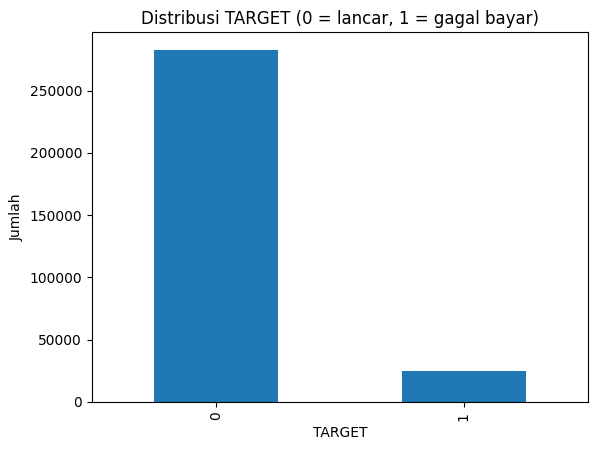


Kolom dengan missing value terbanyak:
COMMONAREA_AVG              69.9%
COMMONAREA_MODE             69.9%
COMMONAREA_MEDI             69.9%
NONLIVINGAPARTMENTS_MEDI    69.4%
NONLIVINGAPARTMENTS_MODE    69.4%
NONLIVINGAPARTMENTS_AVG     69.4%
FONDKAPREMONT_MODE          68.4%
LIVINGAPARTMENTS_AVG        68.4%
LIVINGAPARTMENTS_MEDI       68.4%
LIVINGAPARTMENTS_MODE       68.4%
FLOORSMIN_MODE              67.8%
FLOORSMIN_AVG               67.8%
FLOORSMIN_MEDI              67.8%
YEARS_BUILD_AVG             66.5%
YEARS_BUILD_MODE            66.5%
dtype: object
Jumlah kolom dengan >50% missing: 41


In [23]:
vc = app['TARGET'].value_counts()
print(vc)
print((app['TARGET'].value_counts(normalize=True) * 100).round(2))

ax = vc.plot(kind='bar', title='Distribusi TARGET (0 = lancar, 1 = gagal bayar)')
ax.set_xlabel('TARGET'); ax.set_ylabel('Jumlah')
plt.show()

miss = app.isna().mean().sort_values(ascending=False)
print('\nKolom dengan missing value terbanyak:')
print((miss.head(15) * 100).round(1).astype(str) + '%')
print('Jumlah kolom dengan >50% missing:', int((miss > 0.5).sum()))

### 4.2 Anomali DAYS_EMPLOYED
Pada tahap ini yang dilakukan adalah memeriksa nilai 365243 hari pada lama bekerja dan membandingkan default rate-nya.

Hasilnya 55.374 baris (18,01%) bernilai 365243. Default rate kelompok ini 5,40%, sedangkan kelompok lainnya 8,66%.

Insight: 365243 hari (sekitar 1.000 tahun) adalah kode khusus, bukan angka asli. Karena default rate-nya berbeda, kode ini membawa informasi sehingga ditandai dengan flag lalu nilainya dikosongkan, bukan dibuang.

In [24]:
# Memeriksa nilai tidak wajar 365243 hari pada lama bekerja, dan membandingkan default rate-nya.
anom = (app['DAYS_EMPLOYED'] == 365243)
print(f'DAYS_EMPLOYED = 365243: {anom.sum():,} baris ({anom.mean()*100:.2f}%)')
print('  default rate kelompok anomali :', round(app.loc[anom, 'TARGET'].mean(), 4))
print('  default rate kelompok lainnya :', round(app.loc[~anom, 'TARGET'].mean(), 4))

DAYS_EMPLOYED = 365243: 55,374 baris (18.01%)
  default rate kelompok anomali : 0.054
  default rate kelompok lainnya : 0.0866


### 4.3 Korelasi dengan TARGET
Pada tahap ini yang dilakukan adalah  mengurutkan fitur numerik berdasarkan korelasinya dengan TARGET.

Hasil: korelasi negatif terkuat dimiliki EXT_SOURCE_3 (-0,179), EXT_SOURCE_2 (-0,161), dan EXT_SOURCE_1 (-0,155). Korelasi positif terkuat dimiliki DAYS_BIRTH (0,078), REGION_RATING_CLIENT_W_CITY (0,061), dan REGION_RATING_CLIENT (0,059).

Insight: skor eksternal yanglebih tinggi berkaitan dengan risiko lebih rendah. Pelanggan yang lebih muda (DAYS_BIRTH lebih besar karena bernilai negatif) cenderung lebih berisiko. Semua korelasi di bawah 0,18, artinya risiko tersebar di banyak fitur, sehingga korelasi hanya gambaran awal.


In [25]:
# Mengurutkan fitur numerik berdasarkan korelasinya dengan `TARGET`.

corr = app.corr(numeric_only=True)['TARGET'].drop('TARGET').sort_values()
print('Paling menurunkan risiko:'); print(corr.head(8))
print('\nPaling meningkatkan risiko:'); print(corr.tail(8))

Paling menurunkan risiko:
EXT_SOURCE_3      -0.1789
EXT_SOURCE_2      -0.1605
EXT_SOURCE_1      -0.1553
DAYS_EMPLOYED     -0.0449
FLOORSMAX_AVG     -0.0440
FLOORSMAX_MEDI    -0.0438
FLOORSMAX_MODE    -0.0432
AMT_GOODS_PRICE   -0.0396
Name: TARGET, dtype: float64

Paling meningkatkan risiko:
REG_CITY_NOT_LIVE_CITY        0.0444
FLAG_EMP_PHONE                0.0460
REG_CITY_NOT_WORK_CITY        0.0510
DAYS_ID_PUBLISH               0.0515
DAYS_LAST_PHONE_CHANGE        0.0552
REGION_RATING_CLIENT          0.0589
REGION_RATING_CLIENT_W_CITY   0.0609
DAYS_BIRTH                    0.0782
Name: TARGET, dtype: float64


### 4.4 Outlier dan Kategori Tidak Valid
Pada tahap ini yang dilakukan adalah  menghitung nilai XNA pada kolom kategorikal dan melihat sebaran AMT_INCOME_TOTAL.

Hasil: XNA muncul pada CODE_GENDER (4 baris) dan ORGANIZATION_TYPE (55.374 baris). Income memiliki median 147.150, persentil 99,5 sebesar 630.000, dan maksimum 117.000.000.

Insight: jumlah XNA pada ORGANIZATION_TYPE sama persis dengan jumlah anomali DAYS_EMPLOYED, sehingga dibiarkan sebagai kategori sendiri. XNA pada CODE_GENDER diganti dengan modus. Income dibatasi di persentil 99,5 tanpa membuang baris karena maksimum jauh di atas nilai wajar.



In [26]:
# Mencari nilai `XNA` pada kolom kategorikal dan mengecek sebaran `AMT_INCOME_TOTAL`.

print('CODE_GENDER:'); print(app['CODE_GENDER'].value_counts())

obj_cols = app.select_dtypes(exclude='number').columns
xna = {c: int((app[c] == 'XNA').sum()) for c in obj_cols if (app[c] == 'XNA').any()}
print('\nKolom kategorikal dengan nilai "XNA":', xna)

print('\nAMT_INCOME_TOTAL: median =', app['AMT_INCOME_TOTAL'].median(),
      '| p99.5 =', app['AMT_INCOME_TOTAL'].quantile(0.995), '| max =', app['AMT_INCOME_TOTAL'].max())

CODE_GENDER:
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

Kolom kategorikal dengan nilai "XNA": {'CODE_GENDER': 4, 'ORGANIZATION_TYPE': 55374}

AMT_INCOME_TOTAL: median = 147150.0 | p99.5 = 630000.0 | max = 117000000.0


### 4.5 Default Rate per Kategori
Pada tahap ini yang dilakukan adalah menghitung default rate dan jumlah pelanggan per kelompok.

Hasil:
- Pendidikan: Lower secondary 10,93%, Secondary 8,94%, Higher education 5,36%, Academic degree 1,83% (hanya 164 baris).
- Tipe penghasilan: Working 9,59%, Commercial associate 7,48%, State servant 5,75%, Pensioner 5,39%.
- Status keluarga: Civil marriage 9,94%, Single 9,81%, Married 7,56%, Widow 5,82%.
- Tipe kontrak: Cash loans 8,35%, Revolving loans 5,48%.

Insight: pendidikan yang lebih tinggi berkaitan dengan default rate lebih rendah. Kelompok berukuran sangat kecil (misalnya Maternity leave 40% dari 5 baris dan Unemployed 36,36% dari 22 baris) tidak bisa disimpulkan.


In [27]:
# Menghitung default rate per kelompok (pendidikan, tipe pekerjaan, status keluarga, tipe kontrak).

for col in ['NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_CONTRACT_TYPE']:
    if col in app.columns:
        t = app.groupby(col)['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False)
        print(f'\nDefault rate per {col}'); print(t)



Default rate per NAME_EDUCATION_TYPE
                                mean   count
NAME_EDUCATION_TYPE                         
Lower secondary               0.1093    3816
Secondary / secondary special 0.0894  218391
Incomplete higher             0.0848   10277
Higher education              0.0536   74863
Academic degree               0.0183     164

Default rate per NAME_INCOME_TYPE
                       mean   count
NAME_INCOME_TYPE                   
Maternity leave      0.4000       5
Unemployed           0.3636      22
Working              0.0959  158774
Commercial associate 0.0748   71617
State servant        0.0575   21703
Pensioner            0.0539   55362
Businessman          0.0000      10
Student              0.0000      18

Default rate per NAME_FAMILY_STATUS
                       mean   count
NAME_FAMILY_STATUS                 
Civil marriage       0.0994   29775
Single / not married 0.0981   45444
Separated            0.0819   19770
Married              0.0756  196432

### 4.6 Duplikat dan Keunikan ID
Pada tahap ini yang dilakukan adalah  mengecek baris duplikat dan keunikan SK_ID_CURR.

Hasil: duplikat 0 dan SK_ID_CURR unik.

Insight: satu baris benar mewakili satu pinjaman, tidak ada pelanggan yang terhitung ganda.

In [28]:
# Mengecek baris duplikat, dan keunikan `SK_ID_CURR`.

print('Duplikat baris application_train:', app.duplicated().sum())
print('SK_ID_CURR unik:', app['SK_ID_CURR'].is_unique)


Duplikat baris application_train: 0
SK_ID_CURR unik: True


# **5. Data Cleaning dan Feature Engineering**

Pada tahap ini yang akan dilakukan adalah mengubah data mentah menjadi satu tabel siap pemodelan.


### 5.1 Tabel application
Pada tahap ini yang dilakukan adalah menandai anomali DAYS_EMPLOYED dengan flag lalu mengosongkan nilainya, mengganti XNA pada CODE_GENDER dengan modus, membatasi AMT_INCOME_TOTAL di persentil 99,5, membuat fitur rasio (kredit terhadap income, cicilan terhadap income, cicilan terhadap kredit, kredit terhadap harga barang, lama bekerja terhadap umur, rata-rata EXT_SOURCE), mengubah kolom DAYS menjadi YEARS, dan mengganti nilai tak hingga dengan nilai kosong.

Hasil: ukuran data menjadi 307.511 baris dan 129 kolom.

Insight: rasio finansial menunjukkan beban cicilan relatif terhadap kemampuan bayar, sehingga biasanya lebih informatif daripada angka mentah.


In [29]:
# 5.1 Tabel application
# Menandai dan memperbaiki anomali, mengganti kategori tidak valid, membatasi outlier income, membuat fitur rasio (kredit/income, cicilan/income, dll.), dan mengubah satuan hari menjadi tahun.

def clean_application(d):
    d = d.copy()

    # Anomali DAYS_EMPLOYED -> flag + NaN
    d['FLAG_DAYS_EMPLOYED_ANOM'] = (d['DAYS_EMPLOYED'] == 365243).astype('int8')
    d['DAYS_EMPLOYED'] = d['DAYS_EMPLOYED'].replace(365243, np.nan)

    # CODE_GENDER 'XNA' -> modus
    mode_gender = d.loc[d['CODE_GENDER'] != 'XNA', 'CODE_GENDER'].mode()[0]
    d['CODE_GENDER'] = d['CODE_GENDER'].replace('XNA', mode_gender)

    # Outlier income -> cap persentil 99.5 (tidak memakai TARGET, jadi tidak menimbulkan kebocoran label)
    d['AMT_INCOME_TOTAL'] = d['AMT_INCOME_TOTAL'].clip(upper=d['AMT_INCOME_TOTAL'].quantile(0.995))

    # Fitur rasio finansial
    d['CREDIT_INCOME_RATIO'] = d['AMT_CREDIT'] / d['AMT_INCOME_TOTAL']
    d['ANNUITY_INCOME_RATIO'] = d['AMT_ANNUITY'] / d['AMT_INCOME_TOTAL']
    d['CREDIT_TERM'] = d['AMT_ANNUITY'] / d['AMT_CREDIT']
    d['CREDIT_GOODS_RATIO'] = d['AMT_CREDIT'] / d['AMT_GOODS_PRICE']
    d['EMPLOYED_BIRTH_RATIO'] = d['DAYS_EMPLOYED'] / d['DAYS_BIRTH']
    d['EXT_SOURCE_MEAN'] = d[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)

    # DAYS_* (negatif) -> YEARS_* (positif) lalu buang kolom aslinya
    days_cols = ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']
    for c in days_cols:
        d[c.replace('DAYS_', 'YEARS_')] = -d[c] / 365
    d = d.drop(columns=days_cols)

    return d.replace([np.inf, -np.inf], np.nan)

df = clean_application(app)
del app
gc.collect()
print('Shape setelah cleaning:', df.shape)


Shape setelah cleaning: (307511, 129)


### Pola Agregasi Tabel Riwayat (5.2 sampai 5.6)
Tabel riwayat memiliki banyak baris per pelanggan, sedangkan model membutuhkan satu baris per pelanggan. Polanya sama: hitung kolom turunan di level baris, kelompokkan per SK_ID_CURR, hitung ringkasan (jumlah, rata-rata, maksimum, dan seterusnya), lalu gabungkan ke tabel utama. Setiap tabel dibaca satu per satu dan langsung dibuang dari memori. Jumlah baris tabel agregat dapat melebihi 307.511 karena tabel riwayat kemungkinan juga memuat pelanggan di application_test. Yang dipakai hanya pelanggan yang ada di application_train saat penggabungan.



In [30]:
# Pola agregasi

def agg_flat(d, key, spec, prefix):
    """groupby + agregasi, nama kolom: PREFIX_KOLOM_FUNGSI. Kolom yang tidak ada di data dilewati."""
    spec = {c: f for c, f in spec.items() if c in d.columns}
    g = d.groupby(key).agg(spec)
    g.columns = [f'{prefix}_{c}_{f}'.upper() for c, f in g.columns]
    return g.reset_index()

### 5.2 Agregasi bureau dan bureau_balance
Pada tahap ini yang dilakukan STATUS bulanan diubah menjadi tingkat keterlambatan, diringkas per kredit, digabung ke bureau, lalu diringkas per pelanggan (jumlah kredit, kredit aktif, keterlambatan, utang, perpanjangan kredit).

Hasil: bureau_agg berukuran 305.811 baris dan 23 kolom.

Insight: riwayat keterlambatan di lembaga lain menggambarkan perilaku bayar pelanggan sebelum mengajukan ke Home Credit.


In [31]:
# 5.2 Agregasi `bureau` + `bureau_balance` → per `SK_ID_CURR`
# Meringkas riwayat bulanan (`bureau_balance`) ke tiap kredit, lalu meringkas semua kredit di biro ke tiap klien (jumlah kredit, kredit aktif, keterlambatan, utang).

STATUS_MAP = {'C': 0, 'X': 0, '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5}
BB_COLS = ['SK_ID_BUREAU', 'BB_MONTHS', 'BB_OVERDUE_MONTHS', 'BB_SEV_MAX', 'BB_SEV_MEAN', 'BB_OVERDUE_RATIO']

if USE_BUREAU_BALANCE:
    bb = read('bureau_balance.csv', usecols=['SK_ID_BUREAU', 'STATUS'])
    # STATUS : tingkat keterlambatan lewat lookup pada kategori (jauh lebih cepat daripada .map pada 27 juta string)
    st = bb['STATUS'].astype('category')
    lut = np.array([STATUS_MAP.get(c, 0) for c in st.cat.categories], dtype='int8')
    codes = st.cat.codes.to_numpy()
    bb['BB_SEV'] = np.where(codes >= 0, lut[codes], 0).astype('int8')
    bb['BB_OVERDUE'] = (bb['BB_SEV'] > 0).astype('int8')
    bb = bb.drop(columns='STATUS')
    del st, codes; gc.collect()

    bb_agg = bb.groupby('SK_ID_BUREAU').agg(
        BB_MONTHS=('BB_SEV', 'size'),
        BB_OVERDUE_MONTHS=('BB_OVERDUE', 'sum'),
        BB_SEV_MAX=('BB_SEV', 'max'),
        BB_SEV_MEAN=('BB_SEV', 'mean'),
    ).reset_index()
    bb_agg['BB_OVERDUE_RATIO'] = bb_agg['BB_OVERDUE_MONTHS'] / bb_agg['BB_MONTHS']
    del bb; gc.collect()
else:
    print('USE_BUREAU_BALANCE = False: bureau_balance dilewati.')
    bb_agg = pd.DataFrame({'SK_ID_BUREAU': np.array([], dtype='int32'),
                           **{c: np.array([], dtype='float32') for c in BB_COLS[1:]}})

bureau = read('bureau.csv', usecols=['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE',
                                     'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_OVERDUE',
                                     'CNT_CREDIT_PROLONG']).merge(bb_agg, on='SK_ID_BUREAU', how='left')
del bb_agg; gc.collect()

bureau['OVERDUE_FLAG'] = (bureau['CREDIT_DAY_OVERDUE'] > 0).astype('int8')
bureau['ACTIVE_FLAG'] = (bureau['CREDIT_ACTIVE'] == 'Active').astype('int8')
bureau['DEBT_RATIO'] = bureau['AMT_CREDIT_SUM_DEBT'] / bureau['AMT_CREDIT_SUM'].replace(0, np.nan)

bureau_agg = agg_flat(bureau, 'SK_ID_CURR', {
    'SK_ID_BUREAU': ['count'],
    'DAYS_CREDIT': ['min', 'max', 'mean'],
    'CREDIT_DAY_OVERDUE': ['max', 'mean'],
    'OVERDUE_FLAG': ['sum'],
    'ACTIVE_FLAG': ['sum'],
    'AMT_CREDIT_SUM': ['sum', 'mean', 'max'],
    'AMT_CREDIT_SUM_DEBT': ['sum', 'mean'],
    'AMT_CREDIT_SUM_OVERDUE': ['sum', 'max'],
    'DEBT_RATIO': ['mean'],
    'CNT_CREDIT_PROLONG': ['sum'],
    'BB_OVERDUE_MONTHS': ['sum', 'mean'],
    'BB_SEV_MAX': ['max'],
    'BB_OVERDUE_RATIO': ['mean'],
}, 'BUREAU')
bureau_agg['BUREAU_ACTIVE_RATIO'] = bureau_agg['BUREAU_ACTIVE_FLAG_SUM'] / bureau_agg['BUREAU_SK_ID_BUREAU_COUNT']
print('bureau_agg:', bureau_agg.shape)
del bureau; gc.collect()


bureau_agg: (305811, 23)


7


### 5.3 Agregasi previous_application
Pada tahap ini yang dilakukan menandai pengajuan disetujui dan ditolak, lalu meringkas per pelanggan (jumlah pengajuan, nilai pengajuan dan kredit, uang muka, tenor, rasio disetujui dan rasio ditolak).

Hasil: prev_agg berukuran 338.857 baris dan 20 kolom.

Insight: riwayat penolakan adalah sinyal risiko, dibahas di insight 6.1.


In [33]:
# 5.3 Agregasi `previous_application` → per `SK_ID_CURR`
# Meringkas pengajuan pinjaman sebelumnya di Home Credit, termasuk rasio disetujui dan rasio ditolak.

prev = read('previous_application.csv', usecols=['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'AMT_ANNUITY',
                                                'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT',
                                                'DAYS_DECISION', 'CNT_PAYMENT'])
prev['APP_CREDIT_RATIO'] = prev['AMT_APPLICATION'] / prev['AMT_CREDIT'].replace(0, np.nan)
prev['IS_APPROVED'] = (prev['NAME_CONTRACT_STATUS'] == 'Approved').astype('int8')
prev['IS_REFUSED'] = (prev['NAME_CONTRACT_STATUS'] == 'Refused').astype('int8')

prev_agg = agg_flat(prev, 'SK_ID_CURR', {
    'SK_ID_PREV': ['count'],
    'AMT_ANNUITY': ['mean', 'max'],
    'AMT_APPLICATION': ['mean', 'max'],
    'AMT_CREDIT': ['mean', 'max', 'sum'],
    'AMT_DOWN_PAYMENT': ['mean'],
    'APP_CREDIT_RATIO': ['mean'],
    'DAYS_DECISION': ['min', 'max', 'mean'],
    'CNT_PAYMENT': ['mean', 'sum'],
    'IS_APPROVED': ['sum'],
    'IS_REFUSED': ['sum'],
}, 'PREV')
prev_agg['PREV_APPROVAL_RATIO'] = prev_agg['PREV_IS_APPROVED_SUM'] / prev_agg['PREV_SK_ID_PREV_COUNT']
prev_agg['PREV_REFUSAL_RATIO'] = prev_agg['PREV_IS_REFUSED_SUM'] / prev_agg['PREV_SK_ID_PREV_COUNT']
print('prev_agg:', prev_agg.shape)
del prev; gc.collect()



prev_agg: (338857, 20)


0


### 5.4 Agregasi POS_CASH_balance
Pada tahap ini yang dilakukan menandai bulan terlambat, lalu meringkas per pelanggan (jumlah bulan, sisa cicilan, keterlambatan, rasio bulan terlambat).

Hasil: pos_agg berukuran 337.252 baris dan 11 kolom.


In [34]:
# 5.4 Agregasi `POS_CASH_balance` → per `SK_ID_CURR`
# Meringkas snapshot bulanan pinjaman POS/cash, terutama keterlambatan (DPD) dan sisa cicilan.

pos = read('POS_CASH_balance.csv', usecols=['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT_FUTURE',
                                           'SK_DPD', 'SK_DPD_DEF'])
pos['IS_DPD'] = (pos['SK_DPD'] > 0).astype('int8')

pos_agg = agg_flat(pos, 'SK_ID_CURR', {
    'SK_ID_PREV': ['nunique'],
    'MONTHS_BALANCE': ['count', 'min'],
    'CNT_INSTALMENT_FUTURE': ['mean'],
    'SK_DPD': ['max', 'mean'],
    'SK_DPD_DEF': ['max', 'mean'],
    'IS_DPD': ['sum'],
}, 'POS')
pos_agg['POS_DPD_RATIO'] = pos_agg['POS_IS_DPD_SUM'] / pos_agg['POS_MONTHS_BALANCE_COUNT']
print('pos_agg:', pos_agg.shape)
del pos; gc.collect()




pos_agg: (337252, 11)


0

### 5.5 Agregasi credit_card_balance
Pada tahap ini yang dilakukan menghitung utilisasi limit dan menandai keterlambatan, lalu meringkas per pelanggan (saldo, limit, utilisasi, penarikan, pembayaran).

Hasil: cc_agg berukuran 103.558 baris dan 16 kolom, jauh lebih sedikit karena tidak semua pelanggan memiliki kartu kredit.


In [35]:
# 5.5 Agregasi `credit_card_balance` → per `SK_ID_CURR`
# Meringkas pemakaian kartu kredit: saldo, utilisasi limit, penarikan, pembayaran, dan keterlambatan.

cc = read('credit_card_balance.csv', usecols=['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE',
                                             'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_CURRENT',
                                             'AMT_PAYMENT_TOTAL_CURRENT', 'SK_DPD'])
cc['IS_DPD'] = (cc['SK_DPD'] > 0).astype('int8')
cc['UTILIZATION'] = cc['AMT_BALANCE'] / cc['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)

cc_agg = agg_flat(cc, 'SK_ID_CURR', {
    'SK_ID_PREV': ['nunique'],
    'MONTHS_BALANCE': ['count'],
    'AMT_BALANCE': ['mean', 'max'],
    'AMT_CREDIT_LIMIT_ACTUAL': ['mean'],
    'UTILIZATION': ['mean', 'max'],
    'AMT_DRAWINGS_CURRENT': ['mean', 'sum'],
    'AMT_PAYMENT_TOTAL_CURRENT': ['mean', 'sum'],
    'SK_DPD': ['max', 'mean'],
    'IS_DPD': ['sum'],
}, 'CC')
cc_agg['CC_DPD_RATIO'] = cc_agg['CC_IS_DPD_SUM'] / cc_agg['CC_MONTHS_BALANCE_COUNT']
print('cc_agg:', cc_agg.shape)
del cc; gc.collect()

cc_agg: (103558, 16)


0


### 5.6 Agregasi installments_payments
Pada tahap ini yang dilakukan adalah  menghitung keterlambatan bayar, penanda telat, selisih pembayaran, dan rasio pembayaran, lalu meringkas per pelanggan termasuk INST_LATE_RATIO.

Hasil: inst_agg berukuran 339.519 baris dan 15 kolom.

Insight: tabel ini memberi gambaran perilaku membayar yang paling langsung.


In [36]:
# 5.6 Agregasi `installments_payments` → per `SK_ID_CURR`
# Menghitung keterlambatan bayar cicilan, selisih jumlah yang dibayar vs seharusnya, dan rasio telat.

inst = read('installments_payments.csv', usecols=['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT',
                                                 'DAYS_ENTRY_PAYMENT', 'AMT_INSTALMENT', 'AMT_PAYMENT'])
inst['DAYS_LATE'] = (inst['DAYS_ENTRY_PAYMENT'] - inst['DAYS_INSTALMENT']).clip(lower=0)
inst['IS_LATE'] = (inst['DAYS_LATE'] > 0).astype('int8')
inst['PAYMENT_SHORTFALL'] = inst['AMT_INSTALMENT'] - inst['AMT_PAYMENT']
inst['PAYMENT_RATIO'] = inst['AMT_PAYMENT'] / inst['AMT_INSTALMENT'].replace(0, np.nan)

inst_agg = agg_flat(inst, 'SK_ID_CURR', {
    'SK_ID_PREV': ['nunique'],
    'NUM_INSTALMENT_NUMBER': ['count'],
    'DAYS_LATE': ['max', 'mean'],
    'IS_LATE': ['sum'],
    'PAYMENT_SHORTFALL': ['sum', 'mean'],
    'PAYMENT_RATIO': ['mean', 'min'],
    'AMT_INSTALMENT': ['sum', 'mean'],
    'AMT_PAYMENT': ['sum', 'mean'],
}, 'INST')
inst_agg['INST_LATE_RATIO'] = inst_agg['INST_IS_LATE_SUM'] / inst_agg['INST_NUM_INSTALMENT_NUMBER_COUNT']
inst_agg = inst_agg.replace([np.inf, -np.inf], np.nan)
print('inst_agg:', inst_agg.shape)
del inst; gc.collect()



inst_agg: (339519, 15)


27


### 5.7 Gabungkan ke Master Dataset
Pada tahap ini yang dilakukan adalah menggabungkan semua agregat ke tabel utama per SK_ID_CURR, menambah penanda HAS_ (1 bila pelanggan punya riwayat), dan mengisi 0 untuk pelanggan tanpa riwayat.

Hasil: master dataset berukuran 307.511 baris dan 214 kolom. Pelanggan dengan riwayat: bureau 85,7%, previous_application 94,6%, POS_CASH 94,1%, kartu kredit 28,3%, dan cicilan 94,8%.

Insight: pelanggan tanpa riwayat bukan data hilang biasa, melainkan memang tidak memiliki produk tersebut. Penanda HAS_ membedakan kondisi itu dari riwayat bernilai 0.

In [37]:
# 5.7 Gabungkan Semua ke Master Dataset
# Menggabungkan semua hasil agregasi ke tabel utama berdasarkan `SK_ID_CURR`, menambah flag `HAS_*`, dan mengisi 0 untuk klien tanpa riwayat.

def add_history(d, agg, name):
    """Merge agregat; flag HAS_<name> = punya riwayat; kolom agregat tanpa riwayat diisi 0."""
    d = d.merge(agg, on='SK_ID_CURR', how='left')
    cols = [c for c in agg.columns if c != 'SK_ID_CURR']
    d[f'HAS_{name}'] = d[cols[0]].notna().astype('int8')
    d[cols] = d[cols].fillna(0)
    return d

for agg, name in [(bureau_agg, 'BUREAU'), (prev_agg, 'PREV'), (pos_agg, 'POS'),
                  (cc_agg, 'CC'), (inst_agg, 'INST')]:
    df = add_history(df, agg, name)
del bureau_agg, prev_agg, pos_agg, cc_agg, inst_agg
gc.collect()

print('Master dataset:', df.shape)
print('Proporsi punya riwayat:', df[[c for c in df.columns if c.startswith('HAS_')]].mean().round(3).to_dict())

df.to_pickle(DATA_DIR + 'master_train.pkl')
print('Tersimpan:', DATA_DIR + 'master_train.pkl')


Master dataset: (307511, 214)
Proporsi punya riwayat: {'HAS_BUREAU': 0.857, 'HAS_PREV': 0.946, 'HAS_POS': 0.941, 'HAS_CC': 0.283, 'HAS_INST': 0.948}
Tersimpan: /content/master_train.pkl


# **6. Insight**

### 6.1 Riwayat Penolakan Pinjaman Sebelumnya
Pada bagian ini yang dilakukan adalah mengelompokkan pelanggan berdasarkan persentase pengajuan sebelumnya yang ditolak, lalu menghitung default rate.

Hasil: tidak pernah ditolak 7,07%, 1 sampai 30% ditolak 8,37%, 31 sampai 60% ditolak 11,86%, di atas 60% ditolak 16,18%. Pelanggan tanpa riwayat 5,96%.

Insight: default rate naik seiring naiknya persentase penolakan. Pelanggan dengan lebih dari 60% penolakan memiliki default rate sekitar 2,3 kali pelanggan yang tidak pernah ditolak.

### 6.2 Riwayat Keterlambatan Cicilan
Pada bagian ini yang dilakukan adalah  mengelompokkan pelanggan berdasarkan persentase cicilan yang telat, lalu menghitung default rate.

Hasil: tidak pernah telat 6,83%, 1 sampai 10% telat 7,92%, 11 sampai 30% telat 10,11%, di atas 30% telat 13,33%. Pelanggan tanpa riwayat 5,99%.

Insight: perilaku telat bayar di masa lalu berkaitan dengan risiko berikutnya. Pelanggan yang di atas 30% telat memiliki default rate sekitar dua kali pelanggan yang tidak pernah telat.

### 6.3 Kombinasi Sinyal: Skor Eksternal Rendah dan Sering Telat Bayar
Pada bagian ini yang dilakukan adalah  menggabungkan dua sinyal menjadi tiga segmen. Skor eksternal rendah berarti rata-rata EXT_SOURCE di bawah persentil ke 20, sering telat berarti rasio cicilan telat di atas 10%.

Hasil: relatif aman 4,74% (186.433 pelanggan), berisiko tunggal 11,68% (102.765), berisiko ganda 21,73% (18.313).

Insight: pelanggan berisiko ganda memiliki default rate 4,58 kali segmen relatif aman, sehingga kombinasi sinyal memisahkan risiko lebih tajam daripada satu sinyal saja.

In [38]:
# 6.1 Riwayat penolakan pinjaman sebelumnya
# Mengelompokkan klien berdasarkan persentase pengajuan sebelumnya yang ditolak, lalu melihat default rate tiap kelompok.

def rate_by_bins(d, col, bins, labels, has_flag, no_hist='Tidak ada riwayat'):
    s = pd.cut(d[col], bins=bins, labels=labels, include_lowest=True).astype(object)
    s = s.where(d[has_flag] == 1, no_hist)
    return d.groupby(s)['TARGET'].agg(['mean', 'count'])

t1 = rate_by_bins(df, 'PREV_REFUSAL_RATIO', [-0.001, 0.0, 0.3, 0.6, 1.0],
                  ['0% ditolak', '1-30% ditolak', '31-60% ditolak', '>60% ditolak'], 'HAS_PREV')
t1



,mean,count
PREV_REFUSAL_RATIO,,
0% ditolak,0.0707,190763
1-30% ditolak,0.0837,53462
31-60% ditolak,0.1186,39433
>60% ditolak,0.1618,7399
Tidak ada riwayat,0.0596,16454


In [39]:
#  6.2 Riwayat keterlambatan cicilan
# Mengelompokkan klien berdasarkan persentase cicilan yang telat dibayar, lalu melihat default rate tiap kelompok.

t2 = rate_by_bins(df, 'INST_LATE_RATIO', [-0.001, 0.0, 0.1, 0.3, 1.0],
                  ['Tidak pernah telat', '1-10% telat', '11-30% telat', '>30% telat'], 'HAS_INST')
t2



,mean,count
INST_LATE_RATIO,,
1-10% telat,0.0792,75517
11-30% telat,0.1011,60096
>30% telat,0.1333,17827
Tidak ada riwayat,0.0599,15922
Tidak pernah telat,0.0683,138149


In [40]:
#  6.3 Kombinasi sinyal: skor eksternal rendah + sering telat bayar
# Menggabungkan dua sinyal berbeda (skor eksternal rendah dan sering telat bayar) menjadi tiga segmen risiko.

low_ext = df['EXT_SOURCE_MEAN'] < df['EXT_SOURCE_MEAN'].quantile(0.2)
high_late = df['INST_LATE_RATIO'] > 0.1
seg = np.where(low_ext & high_late, '3. Berisiko ganda',
      np.where(low_ext | high_late, '2. Berisiko tunggal', '1. Relatif aman'))
t3 = df.groupby(seg)['TARGET'].agg(['mean', 'count'])
t3['lift_vs_aman'] = t3['mean'] / t3.loc['1. Relatif aman', 'mean']
t3

,mean,count,lift_vs_aman
1. Relatif aman,0.0474,186433,1.0000
2. Berisiko tunggal,0.1168,102765,2.4627
3. Berisiko ganda,0.2173,18313,4.5824


# **7. Modeling**

Tujuan: membangun model prediksi gagal bayar dengan setidaknya dua model, termasuk Logistic Regression, lengkap dengan tuning hyperparameter.

### 7.1 Persiapan Fitur dan Pembagian Data
Pada bagian ini yang dilakukan adalah memisahkan target dan fitur, mengubah 16 kolom kategorikal dengan one hot encoding, lalu membagi data secara stratified menjadi train, validation, dan test. Tuning memakai sampel 100.000 baris, sedangkan model final dilatih di seluruh data train.

Hasil: 351 fitur. Train 184.506 baris, validation 61.502, test 61.503. Default rate sama di ketiganya (8,07%).

Insight: pembagian stratified menjaga proporsi gagal bayar tetap sama, dan test dipisahkan sejak awal agar hasil akhir jujur.



In [41]:
# 7.1 Persiapan Fitur & Split Train/Validation/Test (scaling ada di dalam Pipeline)
# Mengubah kolom kategorikal menjadi angka (one-hot), memisahkan fitur dan target, lalu membagi data 60% train, 20% validation, 20% test dengan proporsi target yang sama.

y = df['TARGET'].astype('int8')
credit_amt = df['AMT_CREDIT'].astype('float64')          # untuk hitung dampak bisnis (disimpan sebelum di-drop)
X = df.drop(columns=['TARGET', 'SK_ID_CURR'])

# One-hot untuk kolom non-numerik
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print('Kolom kategorikal:', len(cat_cols))
X = pd.get_dummies(X, columns=cat_cols, dummy_na=True, dtype='int8')
X = X.replace([np.inf, -np.inf], np.nan).astype('float32')
print('Fitur akhir:', X.shape[1])
del df; gc.collect()

# Split 60 / 20 / 20 (stratified)
X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
del X_tmp, y_tmp; gc.collect()
print(f'Train {X_tr.shape} | Val {X_va.shape} | Test {X_te.shape}')
print('Default rate  train/val/test:', round(y_tr.mean(), 4), round(y_va.mean(), 4), round(y_te.mean(), 4))

# Subsample untuk tuning (menghemat waktu); model final tetap di-fit di seluruh train
TUNE_N = 100_000
if len(X_tr) > TUNE_N:
    X_s, _, y_s, _ = train_test_split(X_tr, y_tr, train_size=TUNE_N, stratify=y_tr, random_state=SEED)
else:
    X_s, y_s = X_tr, y_tr
print('Data untuk tuning:', X_s.shape)


Kolom kategorikal: 16
Fitur akhir: 351
Train (184506, 351) | Val (61502, 351) | Test (61503, 351)
Default rate  train/val/test: 0.0807 0.0807 0.0807
Data untuk tuning: (100000, 351)


### 7.2 Strategi Model dan Tuning
Tiga model dibandingkan adalah Logistic Regression (model wajib, baseline yang mudah dijelaskan), HistGradientBoosting (boosting yang menangani nilai kosong secara native), dan Random Forest (pembanding non linear). Tuning memakai cross validation 3 fold dengan skor ROC-AUC. Model tidak memakai class_weight agar probabilitasnya terkalibrasi.

### 7.3 Logistic Regression
Pada bagian ini yang dilakukan adalah  mencari nilai regularisasi C terbaik dari 0,001; 0,01; 0,1; dan 1,0.

Hasil: C terbaik 0,01 dengan CV AUC 0,7631. Seluruh nilai C menghasilkan skor yang berdekatan (0,7621 sampai 0,7631).

Interpretasi: pemilihan C hampir tidak memengaruhi performa, sehingga model ini stabil terhadap regularisasi.



In [42]:
# Logistic Regression
lr_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('sc', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000)),
])
lr_search = GridSearchCV(lr_pipe, {'clf__C': [0.001, 0.01, 0.1, 1.0]},
                         scoring='roc_auc', cv=3, n_jobs=1, verbose=1)
lr_search.fit(X_s, y_s)
print('LR  best params:', lr_search.best_params_, '| CV AUC:', round(lr_search.best_score_, 4))
print(pd.DataFrame(lr_search.cv_results_)[['param_clf__C', 'mean_test_score', 'std_test_score']])

Fitting 3 folds for each of 4 candidates, totalling 12 fits
LR  best params: {'clf__C': 0.01} | CV AUC: 0.7631
   param_clf__C  mean_test_score  std_test_score
0        0.0010           0.7628          0.0010
1        0.0100           0.7631          0.0018
2        0.1000           0.7626          0.0020
3        1.0000           0.7621          0.0019


### 7.4 HistGradientBoosting dan Random Forest
Pada bagian ini yang dilakukan adalah mencari kombinasi hyperparameter dengan RandomizedSearchCV, lalu melatih ulang ketiga model terbaik di seluruh data train.

Hasil: HistGradientBoosting memiliki CV AUC 0,7719 (learning rate 0,03, 400 iterasi, kedalaman 6, 15 daun maksimum, daun minimum 20, regularisasi L2 1,0). Random Forest memiliki CV AUC 0,7542 (100 pohon, kedalaman 12, daun minimum 100, max_features sqrt).

Interpretasi: HistGradientBoosting unggul di tahap tuning, diikuti Logistic Regression, lalu Random Forest.

In [43]:
# HistGradientBoosting
hgb_grid = {
    'learning_rate': [0.03, 0.05, 0.1],
    'max_iter': [200, 400],
    'max_depth': [4, 6, None],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [20, 100],
    'l2_regularization': [0.0, 1.0, 10.0],
}
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(early_stopping=True, random_state=SEED),
    hgb_grid, n_iter=8, scoring='roc_auc', cv=3, random_state=SEED, n_jobs=1, verbose=1)
hgb_search.fit(X_s, y_s)
print('HGB best params:', hgb_search.best_params_, '| CV AUC:', round(hgb_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
HGB best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 400, 'max_depth': 6, 'learning_rate': 0.03, 'l2_regularization': 1.0} | CV AUC: 0.7719


In [45]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
rf_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('clf', RandomForestClassifier(max_samples=0.5, n_jobs=-1, random_state=SEED)),
])
rf_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [8, 12],
    'clf__min_samples_leaf': [20, 50, 100],
    'clf__max_features': ['sqrt', 0.3],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_grid, n_iter=4, scoring='roc_auc', cv=3,
                               random_state=SEED, n_jobs=1, verbose=1)
rf_search.fit(X_s, y_s)
print('RF  best params:', rf_search.best_params_, '| CV AUC:', round(rf_search.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
RF  best params: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 100, 'clf__max_features': 'sqrt', 'clf__max_depth': 12} | CV AUC: 0.7542


In [46]:
# Fit ulang model terbaik di SELURUH data train
lr_final = clone(lr_search.best_estimator_).fit(X_tr, y_tr)
hgb_final = clone(hgb_search.best_estimator_).fit(X_tr, y_tr)
rf_final = clone(rf_search.best_estimator_).fit(X_tr, y_tr)

models = {'Logistic Regression': lr_final, 'HistGradientBoosting': hgb_final, 'Random Forest': rf_final}
p_va = {n: m.predict_proba(X_va)[:, 1] for n, m in models.items()}
p_te = {n: m.predict_proba(X_te)[:, 1] for n, m in models.items()}
print('Selesai.')

Selesai.


#8. **Evaluasi Model**

### 8.1 Perbandingan Model
Pada tahap ini yang dilakukan adalah  menghitung ROC-AUC dan PR-AUC tiap model di validation dan test, memilih model terbaik dari validation, lalu menggambar kurva ROC dan Precision Recall di test.
Hasil (test):
- Logistic Regression: ROC-AUC 0,7724, PR-AUC 0,2632
- HistGradientBoosting: ROC-AUC 0,7815, PR-AUC 0,2808
- Random Forest: ROC-AUC 0,7665, PR-AUC 0,2544
Baseline PR-AUC acak adalah 0,0807. Model terbaik berdasarkan validation adalah HistGradientBoosting (ROC-AUC 0,7773).
Interpretasi: ROC-AUC sekitar 0,78 tergolong baik untuk data kredit. PR-AUC terbaik sekitar 3,5 kali baseline acak. Logistic Regression hanya sedikit di bawah HistGradientBoosting (selisih 0,009), sehingga model yang mudah dijelaskan tetap kompetitif.



--- VALIDATION (PR-AUC baseline acak = 0.0807) ---
--- TEST (PR-AUC baseline acak = 0.0807) ---


,ROC-AUC,PR-AUC
model,,
Logistic Regression,0.7680,0.2471
HistGradientBoosting,0.7773,0.2623
Random Forest,0.7601,0.2402


,ROC-AUC,PR-AUC
model,,
Logistic Regression,0.7724,0.2632
HistGradientBoosting,0.7815,0.2808
Random Forest,0.7665,0.2544


Model terbaik (berdasarkan validation): HistGradientBoosting


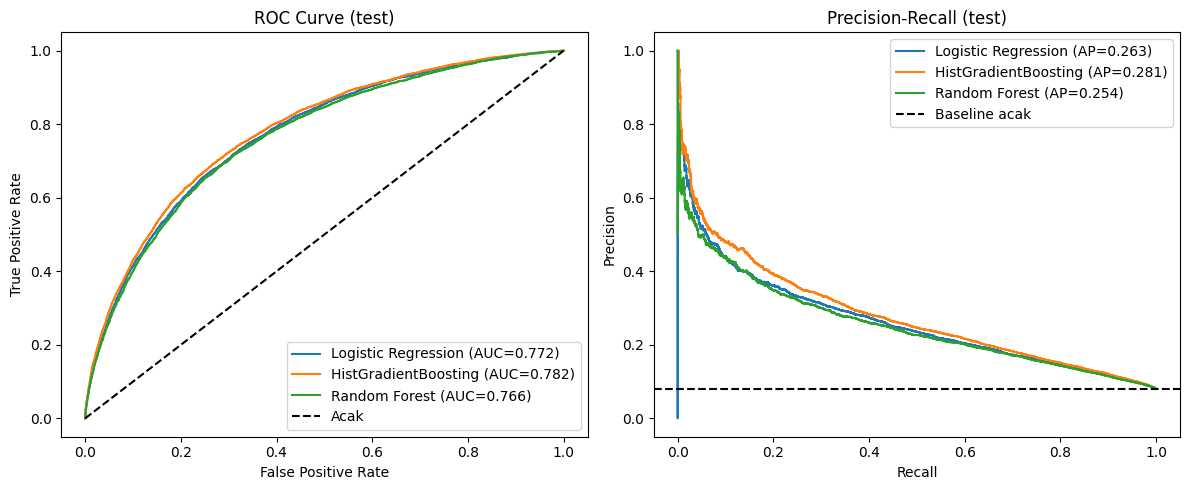

In [47]:
# 8.1 Perbandingan Model
# Menghitung ROC-AUC dan PR-AUC tiap model di validation dan test, menggambar kurva ROC dan Precision-Recall, lalu memilih model terbaik berdasarkan validation.

def summarize(p_dict, y_true, label):
    rows = []
    for n, p in p_dict.items():
        rows.append({'model': n, 'ROC-AUC': roc_auc_score(y_true, p),
                     'PR-AUC': average_precision_score(y_true, p)})
    out = pd.DataFrame(rows).set_index('model')
    print(f'--- {label} (PR-AUC baseline acak = {y_true.mean():.4f}) ---')
    return out

res_va = summarize(p_va, y_va, 'VALIDATION')
res_te = summarize(p_te, y_te, 'TEST')
display(res_va); display(res_te)

best_name = res_va['ROC-AUC'].idxmax()
print('Model terbaik (berdasarkan validation):', best_name)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for n, p in p_te.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    ax[0].plot(fpr, tpr, label=f'{n} (AUC={roc_auc_score(y_te, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax[1].plot(rc, pr, label=f'{n} (AP={average_precision_score(y_te, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', label='Acak'); ax[0].set_title('ROC Curve (test)')
ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate'); ax[0].legend()
ax[1].axhline(y_te.mean(), color='k', ls='--', label='Baseline acak'); ax[1].set_title('Precision-Recall (test)')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend()
plt.tight_layout(); plt.show()


### 8.2 Confusion Matrix pada Berbagai Threshold
Pada bagian ini yang dilakukan adalah  untuk model terbaik di validation, menghitung recall, precision, dan persentase pelanggan yang ditandai berisiko pada tiga threshold.

Hasil:
- Threshold 0,18: recall 0,381, precision 0,284, 10,8% pelanggan ditandai
- Threshold 0,30: recall 0,169, precision 0,378, 3,6% ditandai
- Threshold 0,50: recall 0,033, precision 0,553, 0,5% ditandai

Interpretasi: threshold yang lebih rendah menangkap lebih banyak gagal bayar tetapi lebih banyak pelanggan lancar ikut tertandai. Pada threshold 0,50 hampir tidak ada pelanggan yang ditandai karena model tanpa class_weight menghasilkan probabilitas rendah. Itu normal.



In [48]:
# 8.2 Confusion Matrix pada Berbagai Threshold

p_best_va = p_va[best_name]
t_list = sorted(set([round(MARGIN / (MARGIN + LGD), 2), 0.30, 0.50]))
print(f'Model: {best_name} (validation)')
for t in t_list:
    pred = (p_best_va >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_va, pred).ravel()
    print(f'Threshold {t:.2f}: TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,} | '
          f'recall={tp/(tp+fn):.3f} precision={tp/max(tp+fp, 1):.3f} | klien ditandai berisiko={pred.mean()*100:.1f}%')


Model: HistGradientBoosting (validation)
Threshold 0.18: TN=51,779 FP=4,758 FN=3,074 TP=1,891 | recall=0.381 precision=0.284 | klien ditandai berisiko=10.8%
Threshold 0.30: TN=55,159 FP=1,378 FN=4,127 TP=838 | recall=0.169 precision=0.378 | klien ditandai berisiko=3.6%
Threshold 0.50: TN=56,405 FP=132 FN=4,802 TP=163 | recall=0.033 precision=0.553 | klien ditandai berisiko=0.5%


### 8.3 Feature Importance
Pada bagian ini yang dilakukan adalah  menampilkan koefisien Logistic Regression pada fitur yang distandardisasi, dan permutation importance HistGradientBoosting pada grafik.
Hasil: fitur penurun risiko terkuat adalah EXT_SOURCE_3 (-0,271), EXT_SOURCE_2 (-0,221), EXT_SOURCE_MEAN (-0,220), INST_NUM_INSTALMENT_NUMBER_COUNT (-0,185), dan CREDIT_TERM (-0,142). Fitur penaik risiko terkuat adalah ANNUITY_INCOME_RATIO (0,208), BUREAU_ACTIVE_FLAG_SUM (0,192), FLAG_DOCUMENT_3 (0,188), PREV_CNT_PAYMENT_SUM (0,147), dan INST_LATE_RATIO (0,129).
Interpretasi: skor eksternal adalah penurun risiko terkuat. Beban cicilan terhadap income, jumlah kredit aktif di biro, dan keterlambatan cicilan menaikkan risiko. Fitur terkait besar dan jangka waktu cicilan (ANNUITY_INCOME_RATIO, CREDIT_TERM, CREDIT_INCOME_RATIO) masuk sepuluh teratas, sehingga menyesuaikan principal, maturity, dan cicilan memang relevan terhadap risiko.

Meningkatkan risiko (koefisien positif terbesar):
ANNUITY_INCOME_RATIO             0.2082
BUREAU_ACTIVE_FLAG_SUM           0.1920
FLAG_DOCUMENT_3                  0.1882
PREV_CNT_PAYMENT_SUM             0.1468
POS_CNT_INSTALMENT_FUTURE_MEAN   0.1333
INST_LATE_RATIO                  0.1289
AMT_ANNUITY                      0.1256
REGION_RATING_CLIENT_W_CITY      0.1115
FLAG_DOCUMENT_6                  0.1115
PREV_AMT_CREDIT_MAX              0.1113
dtype: float64

Menurunkan risiko (koefisien negatif terbesar):
EXT_SOURCE_3                       -0.2705
EXT_SOURCE_2                       -0.2206
EXT_SOURCE_MEAN                    -0.2203
INST_NUM_INSTALMENT_NUMBER_COUNT   -0.1850
CREDIT_TERM                        -0.1419
AMT_GOODS_PRICE                    -0.1379
PREV_AMT_ANNUITY_MEAN              -0.1311
POS_MONTHS_BALANCE_COUNT           -0.1295
CC_AMT_PAYMENT_TOTAL_CURRENT_SUM   -0.1269
CREDIT_INCOME_RATIO                -0.1128
dtype: float64


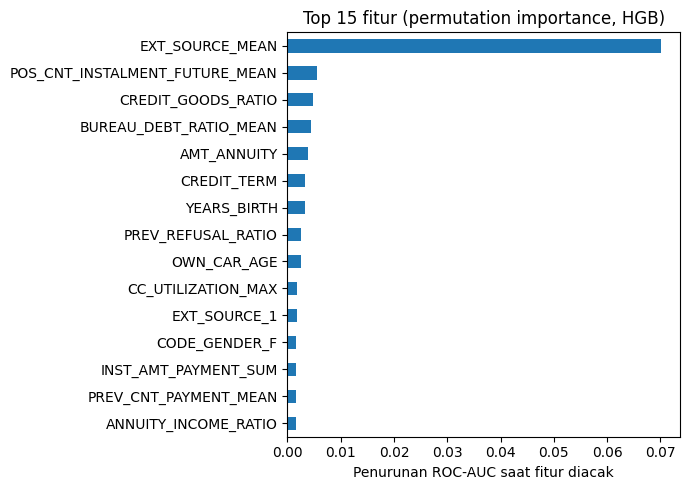

In [49]:
# 8.3 Feature Importance
# Menampilkan koefisien Logistic Regression (arah pengaruh tiap fitur) dan permutation importance HistGradientBoosting (seberapa besar AUC turun kalau fitur diacak).

# Logistic Regression: koefisien pada fitur ter-standardisasi
names = list(X_tr.columns)
coefs = pd.Series(lr_final.named_steps['clf'].coef_[0], index=names).sort_values()
print('Meningkatkan risiko (koefisien positif terbesar):'); print(coefs.tail(10)[::-1])
print('\nMenurunkan risiko (koefisien negatif terbesar):'); print(coefs.head(10))

# HistGradientBoosting: permutation importance di sampel validation
samp = X_va.sample(min(8000, len(X_va)), random_state=SEED)
pi = permutation_importance(hgb_final, samp, y_va.loc[samp.index], scoring='roc_auc',
                            n_repeats=2, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_va.columns).sort_values(ascending=False)
ax = imp.head(15)[::-1].plot(kind='barh', figsize=(7, 5), title='Top 15 fitur (permutation importance, HGB)')
ax.set_xlabel('Penurunan ROC-AUC saat fitur diacak')
plt.tight_layout(); plt.show()



#**9. Dampak Pemodelan dan Rekomendasi**

### 9.1 Logika Keputusan dan Analisis Threshold
Aturan keputusan: pelanggan dengan probabilitas gagal bayar di bawah threshold disetujui, sisanya ditolak. Baseline adalah menyetujui semua pengajuan.
Pada analisis tambahan, hasil per pinjaman dihitung dari AMT_CREDIT: disetujui dan lunas menghasilkan keuntungan sebesar margin (10%), disetujui dan gagal bayar menghasilkan kerugian sebesar LGD (45%), dan ditolak bernilai 0. LGD dan margin adalah asumsi.
Hasil: threshold optimal di validation adalah 0,18, sama dengan threshold teoritis margin dibagi (margin ditambah LGD).
Interpretasi: kesesuaian dengan nilai teoritis menunjukkan probabilitas model terkalibrasi dengan baik.





Model: HistGradientBoosting
Threshold optimal (validation): 0.18 | threshold teoritis: 0.18


,threshold,approval_rate,default_rate_approved,net_outcome,delta_vs_approve_all
0,0.0200,0.1426,0.0111,"540,764,386.4250","-1,603,561,976.3250"
2,0.0600,0.5752,0.0291,"1,877,320,580.1750","-267,005,782.5750"
4,0.1000,0.7485,0.0412,"2,210,869,175.4000","66,542,812.6500"
6,0.1400,0.8382,0.0492,"2,322,377,623.1250","178,051,260.3750"
8,0.1800,0.8919,0.0560,"2,336,564,593.5750","192,238,230.8250"
10,0.2200,0.9266,0.0620,"2,317,676,958.4500","173,350,595.7000"
12,0.2600,0.9487,0.0659,"2,295,879,966.0000","151,553,603.2500"
14,0.3000,0.9640,0.0696,"2,265,669,219.1500","121,342,856.4000"
16,0.3400,0.9754,0.0724,"2,240,050,576.7250","95,724,213.9750"
18,0.3800,0.9829,0.0745,"2,220,036,803.3250","75,710,440.5750"


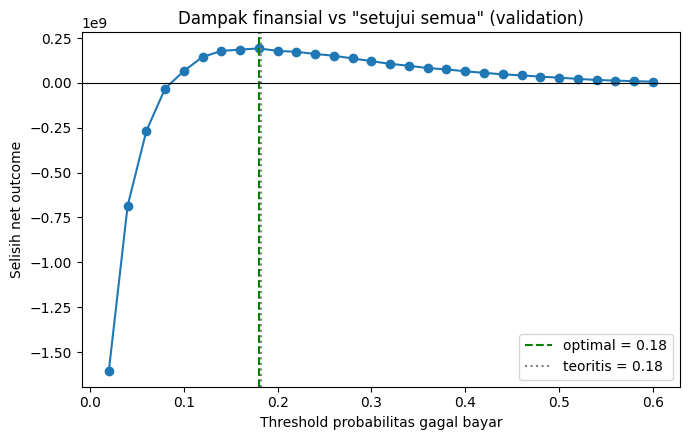

In [50]:
def business_table(proba, y_true, credit, thresholds, lgd=LGD, margin=MARGIN):
    y_a, cr, p = np.asarray(y_true), np.asarray(credit, dtype='float64'), np.asarray(proba)
    base = (cr[y_a == 0] * margin).sum() - (cr[y_a == 1] * lgd).sum()
    rows = []
    for t in thresholds:
        ap = p < t
        net = (cr[ap & (y_a == 0)] * margin).sum() - (cr[ap & (y_a == 1)] * lgd).sum()
        rows.append({'threshold': round(float(t), 3), 'approval_rate': ap.mean(),
                     'default_rate_approved': y_a[ap].mean() if ap.any() else np.nan,
                     'net_outcome': net, 'delta_vs_approve_all': net - base})
    return pd.DataFrame(rows), base

cr_va, cr_te = credit_amt.loc[X_va.index], credit_amt.loc[X_te.index]
grid = np.arange(0.02, 0.62, 0.02)

# Threshold dipilih di VALIDATION
bt_va, base_va = business_table(p_va[best_name], y_va, cr_va, grid)
t_star = float(bt_va.loc[bt_va['net_outcome'].idxmax(), 'threshold'])
t_theory = MARGIN / (MARGIN + LGD)
print(f'Model: {best_name}')
print(f'Threshold optimal (validation): {t_star:.2f} | threshold teoritis: {t_theory:.2f}')
display(bt_va.iloc[::2])

# %%
plt.figure(figsize=(7, 4.5))
plt.plot(bt_va['threshold'], bt_va['delta_vs_approve_all'], marker='o')
plt.axvline(t_star, color='g', ls='--', label=f'optimal = {t_star:.2f}')
plt.axvline(t_theory, color='gray', ls=':', label=f'teoritis = {t_theory:.2f}')
plt.axhline(0, color='k', lw=0.8)
plt.title('Dampak finansial vs "setujui semua" (validation)')
plt.xlabel('Threshold probabilitas gagal bayar'); plt.ylabel('Selisih net outcome')
plt.legend(); plt.tight_layout(); plt.show()



### 9.2 Hasil Akhir di Data Test
Pada bagian ini yang dilakukan adalah  menerapkan threshold 0,18 ke data test dan membandingkannya dengan menyetujui semua pengajuan.
Hasil:
- Tanpa model: approval rate 100%, default rate 8,07%
- Dengan model: approval rate 89,5%, default rate pinjaman yang disetujui 5,60% (proporsi pelanggan yang mampu melunasi 94,40%), turun 30,6% secara relatif
- Selisih net outcome dibanding tanpa model: sekitar 200,6 juta (satuan mata uang AMT_CREDIT)
- Kelas gagal bayar: precision 0,291, recall 0,379, F1-score 0,330. Confusion matrix: TN 51.963, FP 4.575, FN 3.083, TP 1.882
Interpretasi: model menurunkan default rate dengan mengorbankan sekitar 10,5% pengajuan. Namun 4.575 pelanggan lancar (8,1% dari seluruh pelanggan lancar) ikut ditolak, dan hanya sekitar 29% pelanggan yang ditandai benar-benar gagal bayar. Karena itu hasil model lebih tepat dipakai sebagai dasar tiering dan review, bukan penolakan otomatis.



In [51]:
# 9.2 Hasil Akhir di Data TEST (threshold dari validation)
# Menerapkan threshold yang dipilih di validation ke data test, lalu membandingkan default rate, approval rate, dan net outcome dengan kondisi tanpa model.

bt_te, base_te = business_table(p_te[best_name], y_te, cr_te, [t_star])
r = bt_te.iloc[0]
all_default = y_te.mean()
print(f'Tanpa model (setujui semua): approval 100%, default rate {all_default*100:.2f}%')
print(f'Dengan model (threshold {t_star:.2f}): approval {r.approval_rate*100:.1f}%, '
      f'default rate disetujui {r.default_rate_approved*100:.2f}%')
print(f'Penurunan default rate: {(1 - r.default_rate_approved/all_default)*100:.1f}% (relatif)')
print(f'Selisih net outcome vs tanpa model: {r.delta_vs_approve_all:,.0f} (satuan mata uang AMT_CREDIT)')

pred_risky = (p_te[best_name] >= t_star).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred_risky).ravel()
print(f'\nConfusion matrix @ {t_star:.2f}: TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}')
print(classification_report(y_te, pred_risky, target_names=['Lancar', 'Gagal bayar'], digits=3))


Tanpa model (setujui semua): approval 100%, default rate 8.07%
Dengan model (threshold 0.18): approval 89.5%, default rate disetujui 5.60%
Penurunan default rate: 30.6% (relatif)
Selisih net outcome vs tanpa model: 200,639,401 (satuan mata uang AMT_CREDIT)

Confusion matrix @ 0.18: TN=51,963 FP=4,575 FN=3,083 TP=1,882
              precision    recall  f1-score   support

      Lancar      0.944     0.919     0.931     56538
 Gagal bayar      0.291     0.379     0.330      4965

    accuracy                          0.875     61503
   macro avg      0.618     0.649     0.630     61503
weighted avg      0.891     0.875     0.883     61503



### 9.3 Tabel Desil Risiko
Pada bagian ini yang dilakukan adalah  membagi pelanggan test menjadi 10 kelompok berdasarkan skor risiko.
Hasil: desil 10 memiliki default rate 29,64% dan menangkap 36,7% seluruh gagal bayar. Desil 9 sebesar 15,97%, desil 8 sebesar 10,11%, dan desil 1 hanya 1,01%. Dua desil teratas menangkap 56,5% gagal bayar, tiga teratas 69,0%.
Interpretasi: default rate turun konsisten dari desil 10 ke desil 1, artinya model mengurutkan risiko dengan baik. Desil 10 memiliki default rate sekitar 3,7 kali rata-rata populasi.



,jumlah,gagal_bayar,default_rate,rata2_prob,cum_capture
desil,,,,,
10,6151,1823,0.2964,0.2903,0.3672
9,6150,982,0.1597,0.1469,0.5650
8,6150,622,0.1011,0.0999,0.6902
7,6150,436,0.0709,0.0730,0.7780
6,6150,344,0.0559,0.0558,0.8473
5,6151,257,0.0418,0.0435,0.8991
4,6150,186,0.0302,0.0341,0.9366
3,6150,145,0.0236,0.0268,0.9658
2,6150,108,0.0176,0.0204,0.9875


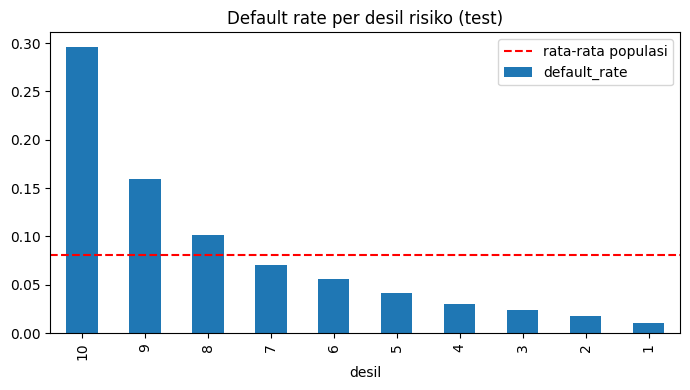

In [52]:
# 9.3 Tabel Desil Risiko (dasar usulan tiering)
# Membagi klien test menjadi 10 kelompok berdasarkan skor risiko, lalu menghitung default rate tiap kelompok.
# Tabel desil risiko (dasar usulan tiering: auto-approve / review / reject)

dec = pd.DataFrame({'p': p_te[best_name], 'y': y_te.values})
dec['desil'] = pd.qcut(dec['p'].rank(method='first'), 10, labels=range(1, 11))
tbl = dec.groupby('desil', observed=True).agg(jumlah=('y', 'size'), gagal_bayar=('y', 'sum'),
                                             default_rate=('y', 'mean'), rata2_prob=('p', 'mean'))
tbl = tbl.sort_index(ascending=False)           # desil 10 = paling berisiko
tbl['cum_capture'] = tbl['gagal_bayar'].cumsum() / tbl['gagal_bayar'].sum()
display(tbl)

ax = tbl['default_rate'].plot(kind='bar', figsize=(7, 4), title='Default rate per desil risiko (test)')
ax.axhline(y_te.mean(), color='r', ls='--', label='rata-rata populasi'); ax.legend(); plt.tight_layout(); plt.show()



### 9.4 Sensitivitas terhadap Asumsi LGD dan Margin
Pada bagian ini yang dilakukan adalah  mengulang analisis untuk LGD 30%, 45%, 60% dan margin 5%, 10%, 15%.
Hasil: threshold optimal berkisar 0,08 sampai 0,34. Pada kesembilan skenario, model selalu memberi selisih net outcome positif dibanding menyetujui semua (sekitar 41,2 juta sampai 693,5 juta).
Interpretasi: kesimpulan bahwa model bermanfaat tidak bergantung pada asumsi tertentu, tetapi threshold ideal bergeser mengikuti rasio margin terhadap LGD.



In [53]:
# 9.4 Sensitivitas terhadap Asumsi LGD dan Margin

rows = []
for lgd in [0.30, 0.45, 0.60]:
    for mg in [0.05, 0.10, 0.15]:
        bv, _ = business_table(p_va[best_name], y_va, cr_va, grid, lgd, mg)
        t = float(bv.loc[bv['net_outcome'].idxmax(), 'threshold'])
        bt, _ = business_table(p_te[best_name], y_te, cr_te, [t], lgd, mg)
        rows.append({'LGD': lgd, 'margin': mg, 'threshold_optimal': t,
                     'approval_rate': bt.loc[0, 'approval_rate'],
                     'default_rate_approved': bt.loc[0, 'default_rate_approved'],
                     'delta_vs_approve_all': bt.loc[0, 'delta_vs_approve_all']})
pd.DataFrame(rows)


,LGD,margin,threshold_optimal,approval_rate,default_rate_approved,delta_vs_approve_all
0,0.3000,0.0500,0.1400,0.8424,0.0491,"186,573,353.6250"
1,0.3000,0.1000,0.2600,0.9510,0.0656,"73,996,693.6500"
2,0.3000,0.1500,0.3400,0.9755,0.0713,"41,216,980.2750"
3,0.4500,0.0500,0.0800,0.6827,0.0346,"411,866,458.2000"
4,0.4500,0.1000,0.1800,0.8950,0.0560,"200,639,400.7500"
5,0.4500,0.1500,0.2600,0.9510,0.0656,"110,995,040.4750"
6,0.6000,0.0500,0.0800,0.6827,0.0346,"693,525,272.1750"
7,0.6000,0.1000,0.1400,0.8424,0.0491,"373,146,707.2500"
8,0.6000,0.1500,0.1800,0.8950,0.0560,"229,057,288.4250"


## 9.5 Kesimpulan dan Rekomendasi
Kesimpulan:
1. Performa: HistGradientBoosting menjadi model terbaik (ROC-AUC test 0,7815), Logistic Regression 0,7724 sebagai pembanding yang mudah dijelaskan.
2. Dampak: pada threshold 0,18, default rate pinjaman yang disetujui turun dari 8,07% menjadi 5,60% dengan approval rate 89,5%.
3. Karakteristik pelanggan berisiko: skor eksternal rendah, rasio cicilan terhadap income tinggi, banyak kredit aktif di biro, riwayat penolakan di atas 60% (default rate 16,18%), cicilan telat di atas 30% (13,33%), dan kombinasi skor rendah dengan sering telat (21,73%).

Rekomendasi:
1. Terapkan tiering berdasarkan desil: desil 1 sampai 6 (default rate sampai 5,59%) disetujui dengan ketentuan standar, desil 7 sampai 9 (7,09% sampai 15,97%) disetujui dengan penyesuaian principal, maturity, atau cicilan, dan desil 10 (29,64%) ditolak atau ditinjau ketat.
2. Beri verifikasi tambahan pada pelanggan dengan sinyal risiko ganda.
3. Jangan memakai threshold 0,50, karena hanya 0,5% pelanggan yang ditandai dan recall 3,3%. Gunakan threshold dari analisis cost benefit dan kalibrasi ulang dengan LGD dan margin aktual.
4. Pantau performa model secara berkala untuk mendeteksi perubahan pola data.

Keterbatasan: LGD dan margin adalah asumsi, evaluasi memakai satu kali pembagian data (bukan berbasis waktu), dan precision kelas gagal bayar masih 29% sehingga sebagian pelanggan lancar tetap tertandai.

In [54]:
# 10. SIMPAN MODEL

import joblib, json, sklearn

OUT_DIR = DATA_DIR
joblib.dump(models[best_name], OUT_DIR + 'model_best.pkl', compress=3)

meta = {
    'columns': list(X_tr.columns),
    'best_model': best_name,
    'threshold': t_star,
    'lgd': LGD, 'margin': MARGIN,
    'sklearn_version': sklearn.__version__,
}
json.dump(meta, open(OUT_DIR + 'meta.json', 'w'))
print('scikit-learn:', sklearn.__version__, '(samakan di requirements.txt)')
print('Model terbaik:', best_name, '| threshold:', t_star)

from google.colab import files
for f in ['model_best.pkl', 'meta.json']:
    files.download(OUT_DIR + f)

scikit-learn: 1.6.1 (samakan di requirements.txt)
Model terbaik: HistGradientBoosting | threshold: 0.18


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>